In [ ]:
import marimo as mo

# Lecture 1: Sweet–Parker scaling in multi-fluid simulations
---

**Goals:**

1.   Reproduce the conservation arguments of the Sweet-Parker theory from direct numerical simulations of nonlinear plasma fluid equations.
2.   Examine what is meant by the concept of "fast" magnetic reconnection in comparison to the original Sweet-Parker theory.
3.   Determine what causes the reconnection to be "fast" by an Ohm's Law analysis of our nonlinear simulations.

---

### Part 1: Some preliminaries

To begin, let us review the equations we will numerically integrate to model magnetic reconnection. We anticipate needing physics "beyond MHD" due to the arguments laid out in last week's class on the Sweet-Parker theory: while resistivity is sufficient non-ideal physics to break field lines, the scaling of the inflow velocity, and thus the rate of magnetic reconnection, is still too slow to explain observations of magnetic reconnection in laboratory, space, and astrophysical plasmas.

We first consider the Vlasov-Maxwell system of equations
\begin{align}
  & \frac{\partial f_s}{\partial t} + \nabla \cdot \left (\mathbf{v} f_s \right ) + \nabla_{\mathbf{v}} \cdot \left ( \frac{q_s}{m_s} \left [\mathbf{E} + \mathbf{v} \times \mathbf{B} \right] f_s \right ) = C[f_s] \\
  & \epsilon_0 \mu_0 \frac{\partial \mathbf{E}}{\partial t} - \nabla \times \mathbf{B} = \mu_0 \mathbf{J}, \qquad \mathbf{J} = \sum_s q_s \int \mathbf{v} f_s \thinspace d\mathbf{v} \\
  & \nabla \cdot \mathbf{E} = \frac{\rho_c}{\epsilon_0}, \qquad \rho_c = \sum_s q_s \int f_s \thinspace d\mathbf{v} \\
  & \frac{\partial \mathbf{B}}{\partial t} + \nabla \times \mathbf{E} = 0, \qquad \nabla \cdot \mathbf{B} = 0
\end{align}

To derive fluid equations from the Vlasov-Maxwell system, we take (mass-weighted) velocity moments of the evolution equation for the distribution function. The simplest sets of fluid equations utilize the zeroth, first, and either scalar second or tensor second moment of the equation. The zeroth moment gives the familiar conservation of mass equation:
\begin{align}
  \frac{\partial \rho_s}{\partial t} + \nabla \cdot \left ( \rho_s \mathbf{u}_s \right ) = 0
\end{align}
The first moment gives the familiar conservation of momentum equation
\begin{align}
  \frac{\partial \rho_s \mathbf{u}_s}{\partial t} + \nabla \cdot \left ( \rho_s \mathbf{u}_s \mathbf{u}_s + \mathbf{P}_s \right ) = \frac{q_s}{m_s} \left ( \rho_s \mathbf{E} + \rho_s \mathbf{u}_s \times \mathbf{B} \right ) + \mathbf{R}
\end{align}
where $\mathbf{P}_s$ is the pressure tensor of species $s$ and $\mathbf{R}$ is an as-yet-unspecified inter-species friction term. For at least one system of equations we will solve today, we will take the inter-species friction to be (for an electron-singly ionized ion plasma):
\begin{align}
  \mathbf{R}_{ei} & = \frac{\rho_e}{\tau_{ei}} \left (\mathbf{u}_e - \mathbf{u}_i \right ),  \\
  \tau_{ei} & = \frac{6 \sqrt{2} \pi^{\frac{3}{2}} \epsilon_0^2 m_i \sqrt{m_e} T_e^{\frac{3}{2}}}{\ln \Lambda e^4 \rho_i}.
\end{align}
If we assume $n_i \approx n_e$, we can see how we can rearrange this inter-species friction term into a more familiar form
\begin{align}
  \mathbf{R}_{ei} & = \frac{\ln \Lambda e^3 \sqrt{m_e} n}{6 \sqrt{2} \pi^{\frac{3}{2}} \epsilon_0^2 T_e^{\frac{3}{2}}} \left (en\mathbf{u}_e - en\mathbf{u}_i \right ) \\
  & =  \frac{\ln \Lambda}{6 \sqrt{2} \pi^{\frac{3}{2}}} \frac{\omega_{pe}}{e n \lambda_{De}^3} \left (en\mathbf{u}_e - en\mathbf{u}_i \right ) \\
  & = -\eta \mathbf{J}
\end{align}
**We will not assume $n_i \approx n_e$ going forward; we have just chosen to illustrate that this form of inter-species friction is a generalization of the resistivity you have been working with up until this point, where now the current density is given by the difference in flows between the electrons and singly-charged ions**

Now we consider the tensor second moment of the Vlasov equation, switching to Einstein summation notation for clarity on the coupling to the rank-3 heat-flux tensor and neglecting the contribution from the collision operator:
\begin{align}
\frac{\partial \mathcal{P}_{ij_s}}{\partial t} + \frac{\partial \mathcal{Q}_{ijk_s}}{\partial x_k} = \frac{q_s}{m_s} \rho_s u_{s[i} E_{j]} + \frac{q_s}{m_s} \epsilon_{[ikl} \mathcal{P}_{kj_s]} B_l
\end{align}
where the square brackets around indices represent the minimal sum over permutations of free indices needed to yield completely symmetric tensors. So for example, $u_{s[i} E_{j]} = u_{i_s} E_j + u_{j_s} E_i$. This tensor second moment $\mathcal{P}_{ij_s} = P_{ij_s} + \rho_s u_{i_s} u_{j_s} = \mathbf{P}_s + \rho_s \mathbf{u}_s \mathbf{u}_s$ is often referred to as the stress tensor and includes both the pressure tensor and Reynolds stress. The rank-3 heat-flux tensor can be written in general as
\begin{align}
  \mathcal{Q}_{ijk_s} = Q_{ijk_s} + u_{s[i} \mathcal{P}_{jk_s]} - 2 \rho_s u_{i_s} u_{j_s} u_{k_s}
\end{align}
where
\begin{align}
  Q_{ijk_s} = \int (v_i - u_{i_s}) (v_j - u_{j_s}) (v_k - u_{k_s}) f_s \thinspace d\mathbf{v}
\end{align}
is the plasma rest-frame heat flux. We now see what is commonly referred to as the "closure" problem as we have 10 equations, 1 from the mass density evolution, 3 from the momentum density evolution, and 6 from the stress tensor evolution, but 20 unknowns thanks to the 10 unknown components for the plasma rest-frame heat flux. To close the system, we must express the plasma rest-frame heat flux in terms of lower moments. A straightforward equation we will use expresses
\begin{align}
  \frac{\partial Q_{ijk_s}}{\partial x_k} & = v_{th_s} k_0 \left (P_{ij_s} - p_s \right ) \\
  p_s & = \frac{1}{3} P_{ii}, \qquad v_{th_s} = \sqrt{\frac{p_s}{\rho_s}}.
\end{align}
In other words, the plasma rest-frame heat flux works to relax the pressure tensor back to isotropy and a scalar pressure at a specified length scale $k_0$.

Based on the form of the tensor second moment equation, or directly from the Vlasov equation **neglecting collisions**, what is the scalar second moment equation for the evolution of the total particle energy?

1.   $\frac{\partial \mathcal{E}_s}{\partial t} + \nabla \cdot \left ( \left [\mathcal{E}_s + p_s\right ] \mathbf{u}_s + \mathbf{q}_s \right ) = \frac{q_s}{m_s} \rho_s \mathbf{u}_s \cdot \mathbf{E}$
2.   $\frac{\partial \mathcal{E}_s}{\partial t} + \nabla \cdot \left ( \left [\mathcal{E}_s + p_s\right ] \mathbf{u}_s + \mathbf{q}_s \right ) = \frac{q_s}{m_s} \left (\rho_s \mathbf{u}_s \cdot \mathbf{E} + \rho_s |\mathbf{u}_s \times \mathbf{B}|^2 \right )$
3.   $\frac{\partial \mathcal{E}_s}{\partial t} + \nabla \cdot \left ( \left [\mathcal{E}_s + p_s\right ] \mathbf{u}_s + \mathbf{q}_s \right ) = 0$
4.   $\frac{\partial \mathcal{E}_s}{\partial t} + \nabla \cdot \left ( \left [\mathcal{E}_s + p_s\right ] \mathbf{u}_s + \mathbf{q}_s \right ) = \mathbf{J}  \cdot \left(\mathbf{u}_s \times \mathbf{B}\right )$

> **Pause and think:** pick an answer before reading on.

To close the fluid equations at this conservation of energy equation, assuming an ideal fluid, we can set $\mathbf{q}_s = 0$ and obtain the scalar pressure via the equation of state, $\mathcal{E}_s = \frac{p_s}{\Gamma - 1} + \frac{1}{2} \rho_s |\mathbf{u}_s|^2$, where $\Gamma$ is the adiabatic index of the fluid.

### Some terminology and helper functions

The coupled set of fluid equations: either the 5 equations from our velocity moments through a scalar second moment, or the 10 equations through the tensor second velocity moment, **we refer to as the 5m and 10m, or 5 moment and 10 moment, multi-fluid equations.** We can solve these equations for any number of species (even mixing some fluids being 5 moment while other fluids are 10 moment) and couple to Maxwell's equations via the current density, which is simply a sum over species of the charge to mass ratio multiplied by the momentum density.

We can now proceed with the necessary preliminaries, including importing our needed Python libraries such as matplotlib and numpy, and defining some helper functions which will be useful for visualizing and analyzing the data.

In [ ]:
import matplotlib
import matplotlib.pyplot as plt
import postgkyl as pg
from postgkyl.diagnostics.mom import five_moment, ten_moment
import numpy as np

In [ ]:
# Helper function for computing vector potential
def calc_psi2d(fx, fy, dx=1, dy=1):#solenoidal flows
	'''
	Calcualte psi by integrating dpsi = -fy*dx + fx*dy, psi[0,0]=0.
	Notes: 
		1. (fx=dpsi/dy,fy=-dpsi/dx) is called Hamiltonian gradient of psi, and	contours of psi give vector field (fx, fy);
		2. div(f)=0
	'''
	ny,nx=fx.shape
	psi=np.zeros((ny,nx))
	for jx in range(1,nx):
		psi[0,jx]=psi[0,jx-1]-fy[0,jx]*dx
	for jy in range(1,ny):
		psi[jy,:]=psi[jy-1,:]+fx[jy,:]*dy
	# since f = rot(A) gives extra restraints on f (e.g., div(f)=0)
	# it makes sense that information provided by fy[1:nx,:] is useless here
	return psi

### Defining our units

When running simulations, it is often convenient to define a set of normalized units in which to perform the simulation. Many physical constants, such as the permittivity of free space, $\epsilon_0 = 8.85 \times 10^{-12} F/m$, or the actual electron and proton mass, $m_e = 9.11\times 10^{-31} kg, m_p = 1.67\times 10^{-27}kg$ respectively, could lead to enhanced truncation error due to finite precision arithmetic if we carried around the physical values of these constants in our simulations.

Below I define the units of the electron-ion multi-fluid magnetic reconnection simulations we have performed.

In [ ]:
# Physical constants and derived parameters
gas_gamma = 5.0 / 3.0 # Adiabatic index.
epsilon0 = 1.0 # Permittivity of free space.
mu0 = 1.0 # Permeability of free space.
light_speed = 1.0/np.sqrt(epsilon0*mu0) # Speed of light. 
mass_ion = 100.0 # Ion mass.
charge_ion = 1.0 # Ion charge.
mass_elc = 1.0 # Electron mass.
charge_elc = -1.0 # Electron charge.
Ti_over_Te = 5.0 # Ion temperature / electron temperature.
n0 = 1.0 # Reference number density.
nb_over_n0 = 0.2 # Background number density / reference number density.
wpi = np.sqrt(charge_ion**2 * n0 / (epsilon0 * mass_ion)) # Ion plasma frequency. 
wpe = np.sqrt(charge_ion**2 * n0 / (epsilon0 * mass_elc)) # Electron plasma frequency. 
di = light_speed/wpi # Ion inertial length. 
de = light_speed/wpe # Electron inertial length. 
B0 = 0.5 # Reference magnetic field strength. Sets ratio of vAe/c. 
beta = 1.0 # Plasma beta.
omega_ci = charge_ion * B0 / mass_ion # Ion cyclotron frequency. 
vA0 = B0/np.sqrt(mu0*n0*mass_ion) # Reference Alfven speed. 
vA_up = B0/np.sqrt(mu0*nb_over_n0*mass_ion) # Upstream reference Alfven speed from background density. 
Lambda_ee = 2.0e5 # Plasma parameter for computing collision time. 
Ti_frac = Ti_over_Te / (1.0 + Ti_over_Te) # Fraction of total temperature from ions.
Te_frac = 1.0 / (1.0 + Ti_over_Te) # Fraction of total temperature from electrons.
T_tot = beta * (B0 * B0) / 2.0 / n0 # Total temperature.
T_elc_ref = T_tot*Te_frac # Reference electron temperature.

After examination of these units, my normalized time, length, and velocity scales are?

1.   $t = \omega_{pe}^{-1} \tilde{t}$, $\mathbf{x} = d_e \tilde{\mathbf{x}}$, $\mathbf{v} = c \tilde{\mathbf{v}}$
2.   $t = \omega_{pi}^{-1} \tilde{t}$, $\mathbf{x} = d_i \tilde{\mathbf{x}}$, $\mathbf{v} = c \tilde{\mathbf{v}}$
3.   $t = \omega_{pe}^{-1} \tilde{t}$, $\mathbf{x} = \lambda_{De} \tilde{\mathbf{x}}$, $\mathbf{v} = v_{th_e} \tilde{\mathbf{v}}$
4.   $t = \Omega_{ci}^{-1} \tilde{t}$, $\mathbf{x} = \rho_i \tilde{\mathbf{x}}$, $\mathbf{v} = v_{th_i} \tilde{\mathbf{v}}$

where $\omega_{ps} = \sqrt{e^2 n_s/\epsilon_0 m_s}$ is the plasma frequency of species $s$, $d_s = c/\omega_{ps}$ is the inertial length of species $s$, $\lambda_{De} = v_{th_e}/\omega_{pe}$ is the Debye length, $\Omega_{ci} = e B_0/m_i$ is the ion cyclotron frequency, and $\rho_i = \sqrt{2} v_{th_i}/\Omega_{ci}$ is the ion gyroradius.

If we include resistivity in our 5 moment calculations, we need to specify the plasma parameter, $\Lambda \sim n \lambda_{De}^3$, to compute the collision time $\tau_{ei}$. In these normalized units, the collision time scales like

1.   $\tau_{ei} \sim \Lambda \tilde{t}$
2.   $\tau_{ei} \sim \ln\Lambda \tilde{t}$
3.   $\tau_{ei} \sim \frac{\Lambda}{\ln\Lambda} \tilde{t}$
4.   $\tau_{ei} \sim \frac{\ln\Lambda}{\Lambda} \tilde{t}$

> **Pause and think:** pick an answer before reading on.

### $\texttt{Gkeyll}$ and $\texttt{postgkyl}$

The code we will be using to model magnetic reconnection is [$\texttt{Gkeyll}$](https://github.com/gkeyllorg/gkeyll), a general purpose simulation framework for a variety of fluid and plasma systems. To read the data, we will utilize the post-processing suite developed alongside $\texttt{Gkeyll}$, [$\texttt{postgkyl}$](https://github.com/gkeyllorg/postgkyl). The *Installing Gkeyll and postgkyl* chapter walks through installing both on your own laptop, and *Running the simulations* shows how to produce the data analyzed here; if the `import postgkyl` above worked, you are ready to go.

The output of $\texttt{Gkeyll}$ simulations can be manipulated in one of two ways: through the GData class, which retains useful metadata from the simulation to subsequent operations, or by directly fetching the raw values and grid and storing them in Numpy arrays for our subsequent manipulations. We will utilize both means of reading the data as we analyze our simulation results.

In [ ]:
import os
from pathlib import Path

# Simulation output lives in ../runs next to this notebook, or wherever GEM_DATA_DIR points
DATA_DIR = Path(os.environ.get("GEM_DATA_DIR", mo.notebook_dir() / ".." / "runs"))

def get_Gdata(pre, frame):
    data_elc = pg.load(str(DATA_DIR / ("%s-elc_%d.gkyl" % (pre, frame))))
    data_ion = pg.load(str(DATA_DIR / ("%s-ion_%d.gkyl" % (pre, frame))))
    data_field = pg.load(str(DATA_DIR / ("%s-field_%d.gkyl" % (pre, frame))))

    return data_elc, data_ion, data_field

In [ ]:
def read_data(data_elc, data_ion, data_field):
    fluid_elc = data_elc.get_values()
    fluid_ion = data_ion.get_values()  
    field = data_field.get_values()  

    # Same grid for all electrons, ions, and EM fields
    # Center the grid values (build a new list so the GData's own cell edges are untouched)
    coords = [0.5*(g[:-1] + g[1:]) for g in data_elc.get_grid()]

    return coords, fluid_elc, fluid_ion, field

### A look at the initial conditions

In the beginning of the tearing mode calculation we started last week, we considered an equilibrium magnetic field profile of the form
\begin{align}
\mathbf{B}(x,y) = B_0 \tanh \left ( \frac{y}{\lambda} \right ) \hat{\mathbf{x}}
\end{align}
Such a magnetic field necessarily has a corresponding current density profile of the form
\begin{align}
  \mathbf{J}(x,y) = -\frac{B_0}{\lambda} \textrm{sech}^2 \left ( \frac{y}{\lambda} \right ) \hat{\mathbf{z}}
\end{align}
Is this a force-free equilibrium? Can we re-write this equilibrium as $\nabla \times \mathbf{B} = \alpha \mathbf{B}$ for some $\alpha$?

1.   Yes
2.   No

If this equilibrium is not force-free, what pressure profile do we need to satisfy force-balance?

1.   No pressure is needed; this equilibrium is force-free
2.   $p \propto \textrm{sech}^2 \left ( \frac{y}{\lambda} \right )$
3.   $p \propto \tanh \left ( \frac{y}{\lambda} \right ) \textrm{sech}^2 \left ( \frac{y}{\lambda} \right )$
4.   $p \propto \tanh \left ( \frac{y}{\lambda} \right )$

> **Pause and think:** pick an answer before reading on.

Let's visualize our equilibrium from our simulations. Since the equilibrium only requires the lowest moments, the equilibrium is identical in both 5-moment and 10-moment.

In [ ]:
_data_elc, data_ion, data_field = get_Gdata('resistive_gem_mass100/rt_5m_resistive_gem', 0)
r_coords, r_fluid_elc, r_fluid_ion, r_field = read_data(_data_elc, data_ion, data_field)

In [ ]:
# Compute out-of-plane current density
Nx = r_fluid_ion.shape[0]
Ny = r_fluid_ion.shape[1]
Jz = np.zeros((Nx, Ny))
Jz = charge_ion / mass_ion * r_fluid_ion[..., 3] + charge_elc / mass_elc * r_fluid_elc[..., 3]
# Compute contours of the magnetic field.
Bx = r_field[..., 3]
_By = r_field[..., 4]
_dx = r_coords[0][1] - r_coords[0][0]
_dy = r_coords[1][1] - r_coords[1][0]
psi = np.zeros((Ny, Nx))
psi = calc_psi2d(Bx.transpose(), _By.transpose(), _dx, _dy)

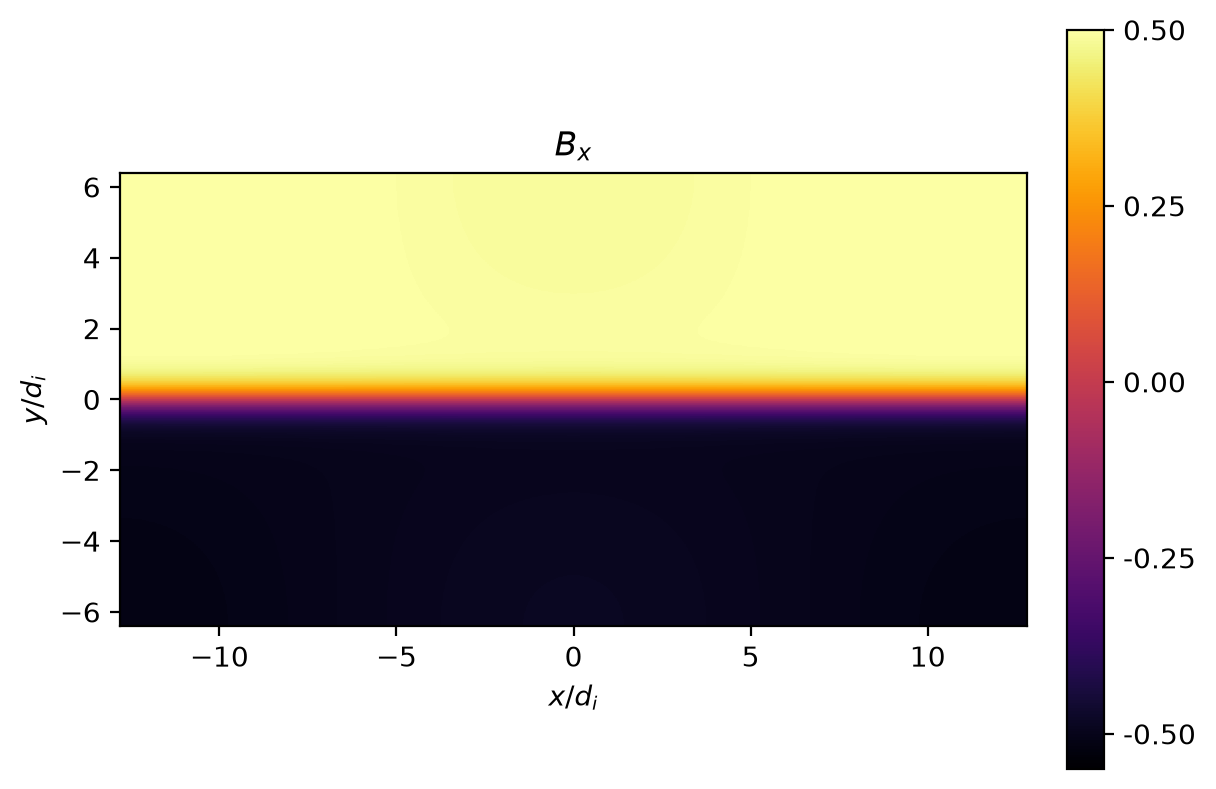

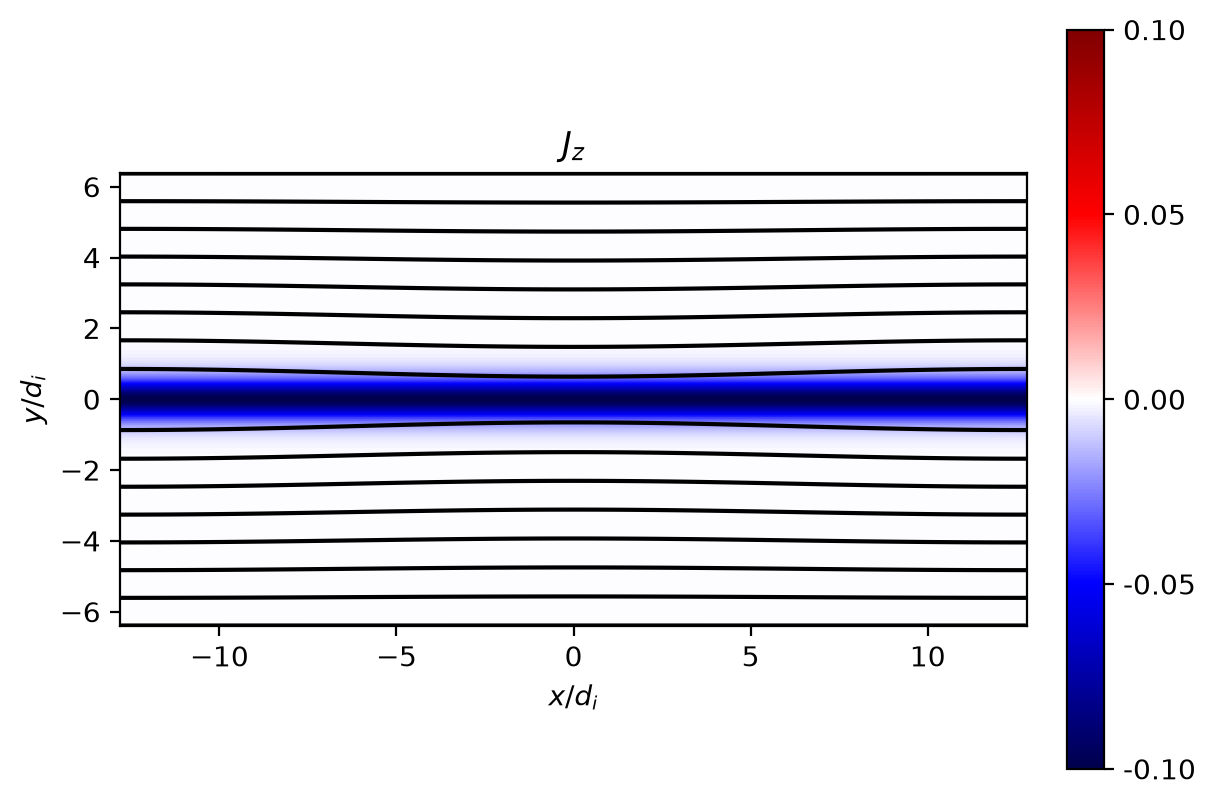

In [ ]:
plt.figure()
# Add shading='gouraud' for further interpolation and smoother plots
plt.pcolormesh(r_coords[0] / di, r_coords[1] / di, Bx.transpose(), vmax=-0.5, vmin=0.5, cmap='inferno')  #, shading='gouraud')
plt.colorbar(format='%.2f', ticks=np.linspace(-0.5, 0.5, 5), fraction=0.046, pad=0.04)
plt.xlabel('$x/d_i$')
plt.ylabel('$y/d_i$')
plt.title('$B_x$')
plt.setp(plt.gca(), aspect=1.0)
_vmax = np.max(np.abs(Jz))
_vmin = -_vmax
plt.figure()
plt.pcolormesh(r_coords[0] / di, r_coords[1] / di, Jz.transpose(), vmax=_vmax, vmin=_vmin, cmap='seismic')
plt.colorbar(format='%.2f', ticks=np.linspace(_vmin, _vmax, 5), fraction=0.046, pad=0.04)
plt.contour(r_coords[0] / di, r_coords[1] / di, psi, 7, colors='k', linestyles='solid')  #, shading='gouraud')
plt.xlabel('$x/d_i$')
plt.ylabel('$y/d_i$')
plt.title('$J_z$')
plt.setp(plt.gca(), aspect=1.0)
plt.show()

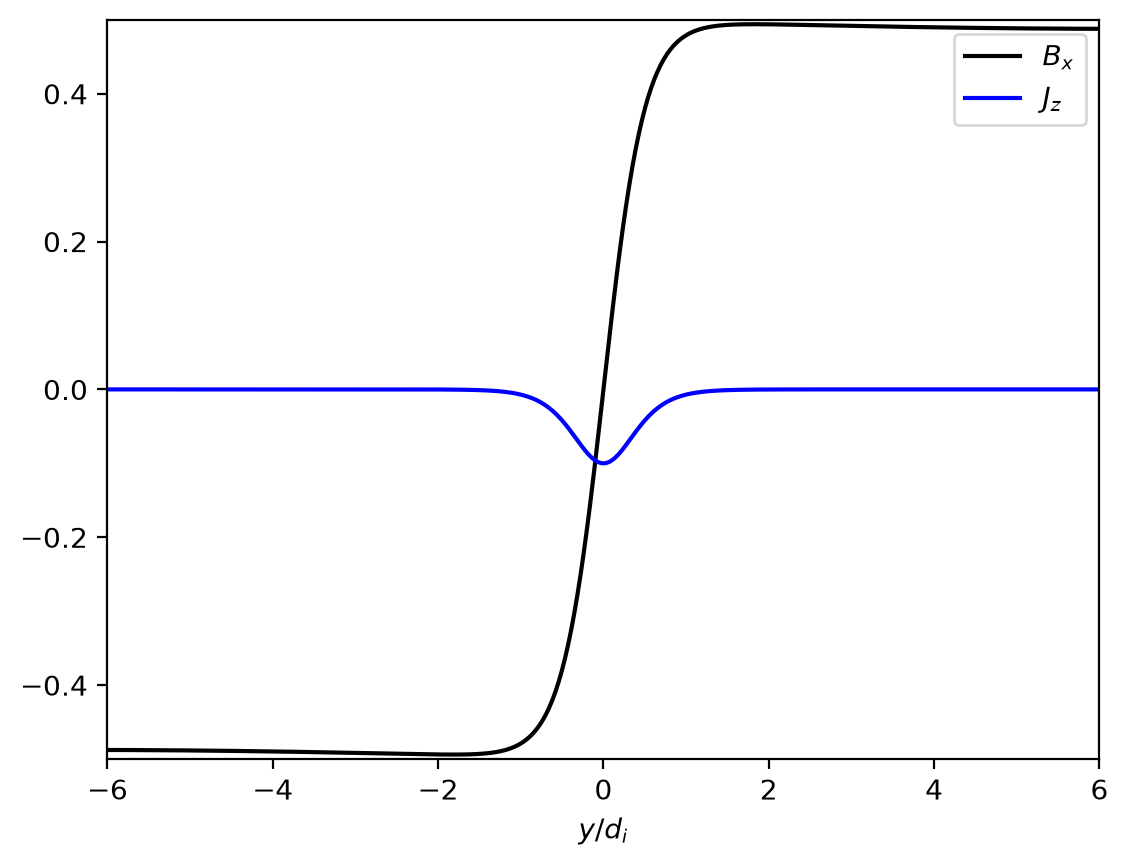

In [ ]:
# Plot Bx and Jz at x=0
x0 = int(Nx/2)
plt.figure()
plt.plot(r_coords[1]/di, Bx[x0,...], 'k', label=r'$B_x$')
plt.plot(r_coords[1]/di, Jz[x0,...], 'b', label=r'$J_z$')
plt.xlabel(r'$y/d_i$')
plt.xlim(-6.0, 6.0)
plt.ylim(-0.5, 0.5)
plt.legend(loc='best')
plt.show()

### A look later in time

Let's look at the simulation later in time to see the fully developed reconnection. You can feel free to switch between visualizing the 10 moment and 5 moment data, or even adding your own calls to the read and plot routines to visualize the development in time.

**We have written out the data every $\Delta t_{IO} = 0.5 \Omega_{ci}^{-1}$ to time $t_{end} = 30 \Omega_{ci}^{-1}$ for a total of 60 frames**.

In [ ]:
_data_elc, data_ion_1, data_field_1 = get_Gdata('resistive_gem_mass100/rt_5m_resistive_gem', 60)
r_coords_1, r_fluid_elc_1, r_fluid_ion_1, r_field_1 = read_data(_data_elc, data_ion_1, data_field_1)

In [ ]:
Nx_1 = r_fluid_ion_1.shape[0]
Ny_1 = r_fluid_ion_1.shape[1]
Jz_1 = np.zeros((Nx_1, Ny_1))
Jz_1 = charge_ion / mass_ion * r_fluid_ion_1[..., 3] + charge_elc / mass_elc * r_fluid_elc_1[..., 3]
Bx_1 = r_field_1[..., 3]
_By = r_field_1[..., 4]
_dx = r_coords_1[0][1] - r_coords_1[0][0]
_dy = r_coords_1[1][1] - r_coords_1[1][0]
psi_1 = np.zeros((Ny_1, Nx_1))
psi_1 = calc_psi2d(Bx_1.transpose(), _By.transpose(), _dx, _dy)

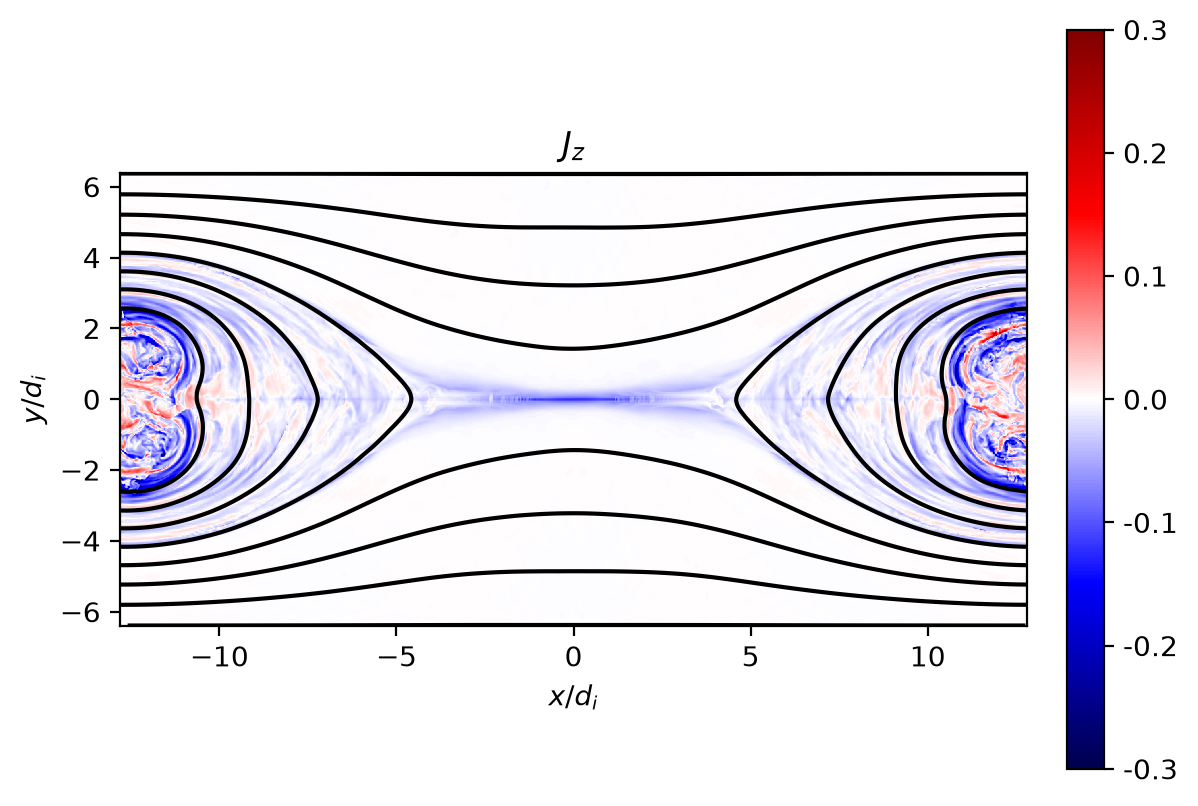

In [ ]:
_vmax = np.max(np.abs(Jz_1))
_vmin = -_vmax
plt.figure()
plt.pcolormesh(r_coords_1[0] / di, r_coords_1[1] / di, Jz_1.transpose(), vmax=_vmax, vmin=_vmin, cmap='seismic')
plt.colorbar(format='%.1f', ticks=np.linspace(_vmin, _vmax, 7), fraction=0.046, pad=0.04)
plt.contour(r_coords_1[0] / di, r_coords_1[1] / di, psi_1, 7, colors='k', linestyles='solid')
plt.xlabel('$x/d_i$')
plt.ylabel('$y/d_i$')
plt.title('$J_z$')
plt.setp(plt.gca(), aspect=1.0)
plt.show()

### Determining the scaling of the in-flows and out-flows: how good is the Sweet-Parker argument?

We now will address the first of our goals today: reconstructing the conservation arguments which Sweet and Parker utilized originally to argue for magnetic reconnection as a possible energy conversion process in observed phenomena such as solar flares. First let us confirm the simulation is behaving as we expect; is the magnetic field vanishing at the X-point? Can we intuitively see that some energy conversion process must be occurring?

In [ ]:
# Compute |B|^2 and |B|
magB_sq = pg.magsq(data_field_1, coords='3:6').get_values()
magB = np.sqrt(magB_sq[..., 0])

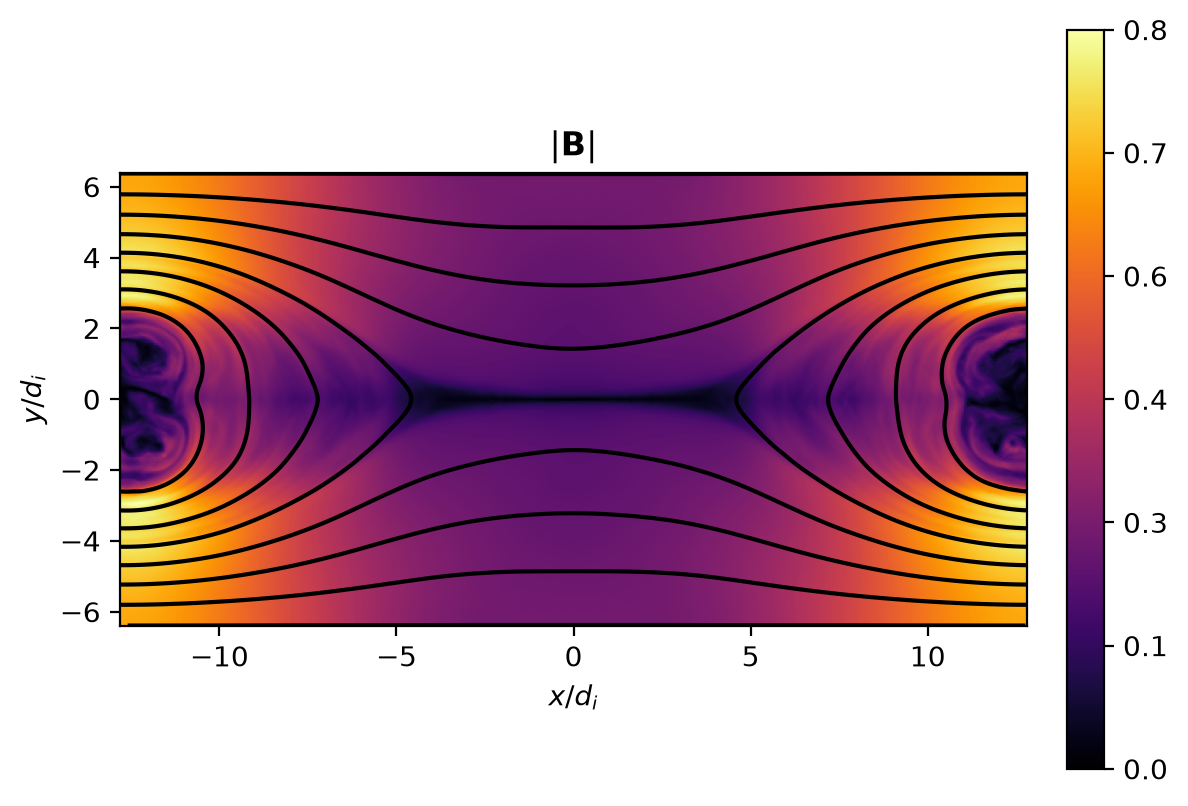

In [ ]:
_vmax = np.max(magB)
_vmin = 0.0
plt.figure()
plt.pcolormesh(r_coords_1[0] / di, r_coords_1[1] / di, magB.transpose(), vmax=_vmax, vmin=_vmin, cmap='inferno')
plt.colorbar(format='%.1f', ticks=np.linspace(_vmin, _vmax, 7), fraction=0.046, pad=0.04)
plt.contour(r_coords_1[0] / di, r_coords_1[1] / di, psi_1, 7, colors='k', linestyles='solid')
plt.xlabel('$x/d_i$')
plt.ylabel('$y/d_i$')
plt.title('$|\\mathbf{B}|$')
plt.setp(plt.gca(), aspect=1.0)
plt.show()

Since the Alfvén speed is a useful normalization when examining the flows produced by the reconnection, let's visualize the local Alfvén speed now from this local magnetic field magnitude.

In [ ]:
# Compute vA = |B|/sqrt(mu_0 rho_i)
rho_ion = five_moment.density(data_ion_1).get_values()
vA = magB / np.sqrt(mu0 * rho_ion[..., 0])

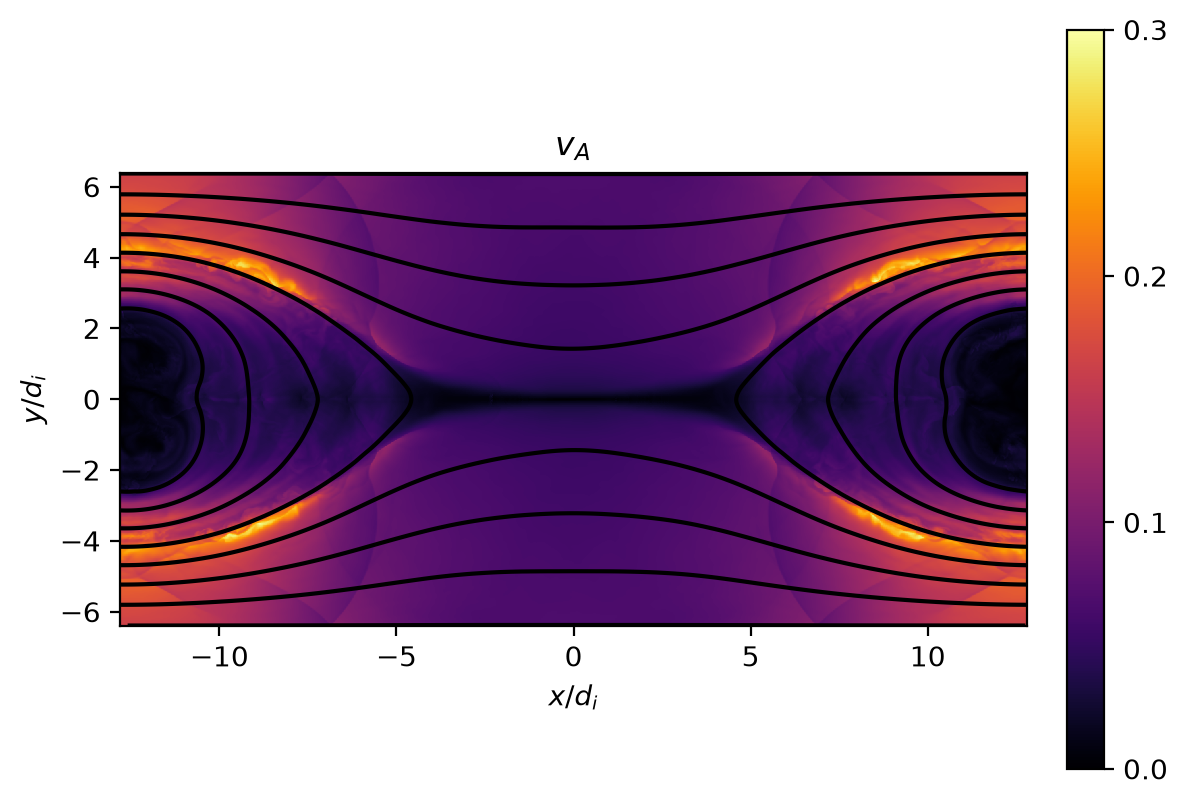

In [ ]:
_vmax = np.max(vA)
_vmin = 0.0
plt.figure()
plt.pcolormesh(r_coords_1[0] / di, r_coords_1[1] / di, vA.transpose(), vmax=_vmax, vmin=_vmin, cmap='inferno')
plt.colorbar(format='%.1f', ticks=np.linspace(_vmin, _vmax, 4), fraction=0.046, pad=0.04)
plt.contour(r_coords_1[0] / di, r_coords_1[1] / di, psi_1, 7, colors='k', linestyles='solid')
plt.xlabel('$x/d_i$')
plt.ylabel('$y/d_i$')
plt.title('$v_A$')
plt.setp(plt.gca(), aspect=1.0)
plt.show()

We have a couple different options for normalizing our in-flow and out-flow velocities. Let's visualize both!

In [ ]:
ux = five_moment.xvel(data_ion_1).get_values()
ux_norm0 = ux[..., 0] / vA_up
ux_norm = ux[..., 0] / vA

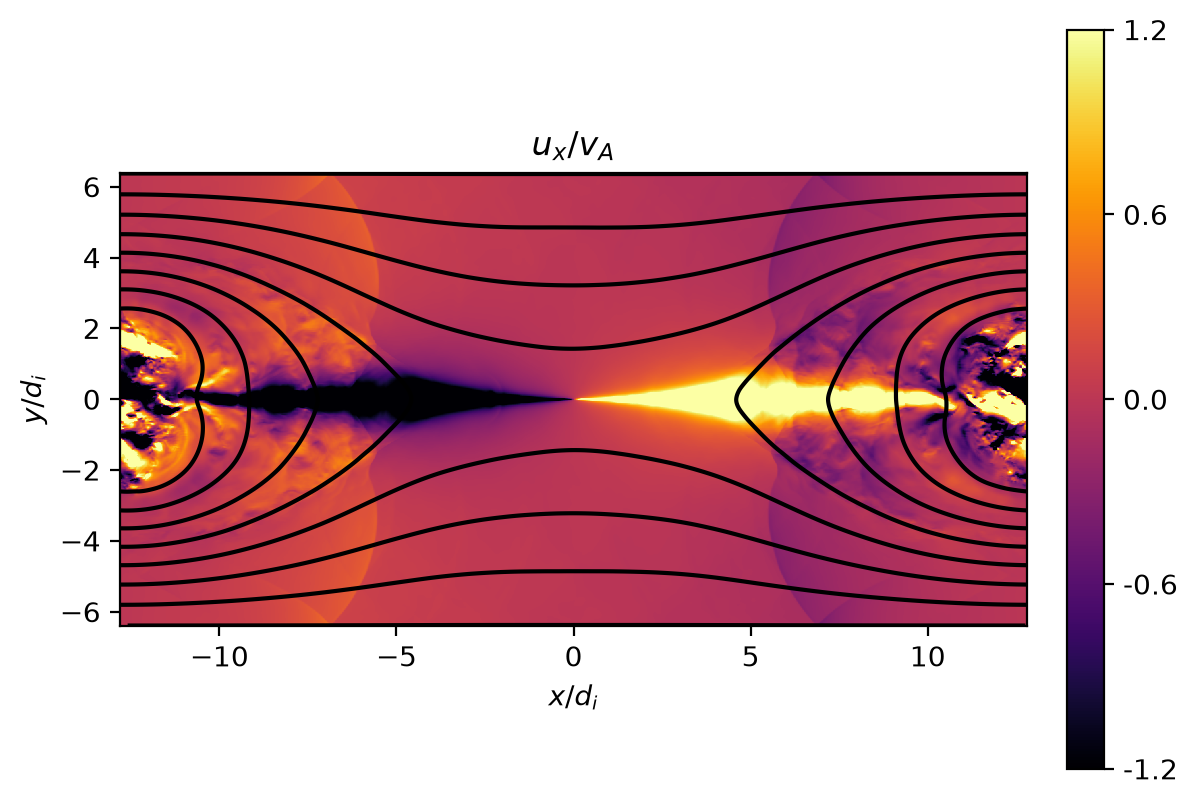

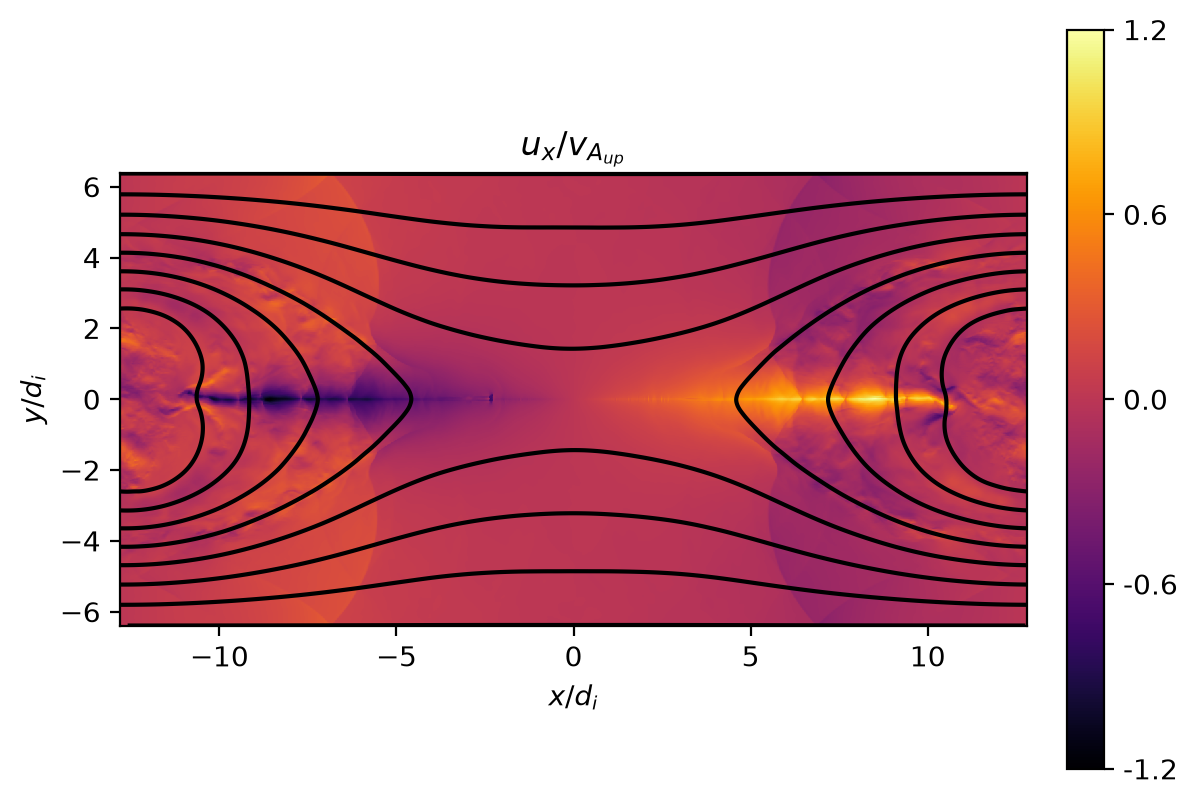

In [ ]:
_vmax = np.max(np.abs(ux_norm0))
_vmin = -_vmax
plt.figure()
plt.pcolormesh(r_coords_1[0] / di, r_coords_1[1] / di, ux_norm.transpose(), vmax=_vmax, vmin=_vmin, cmap='inferno')
plt.colorbar(format='%.1f', ticks=np.linspace(_vmin, _vmax, 5), fraction=0.046, pad=0.04)
plt.contour(r_coords_1[0] / di, r_coords_1[1] / di, psi_1, 7, colors='k', linestyles='solid')
plt.xlabel('$x/d_i$')
plt.ylabel('$y/d_i$')
plt.title('$u_x/v_A$')
plt.setp(plt.gca(), aspect=1.0)
plt.figure()
plt.pcolormesh(r_coords_1[0] / di, r_coords_1[1] / di, ux_norm0.transpose(), vmax=_vmax, vmin=_vmin, cmap='inferno')
plt.colorbar(format='%.1f', ticks=np.linspace(_vmin, _vmax, 5), fraction=0.046, pad=0.04)
plt.contour(r_coords_1[0] / di, r_coords_1[1] / di, psi_1, 7, colors='k', linestyles='solid')
plt.xlabel('$x/d_i$')
plt.ylabel('$y/d_i$')
plt.title('$u_x/v_{A_{up}}$')
plt.setp(plt.gca(), aspect=1.0)
plt.show()

And let's also take cuts of these quantities along $y=0$ to see the ion out-flow, $u_x$, along the X-line. We can also plot the out-of-plane current density, $J_z$,  along $y=0$ to estimate the length of the reconnecting current sheet, $L$. Is this what we expect? What should the outflow be based on Sweet and Parker's conservation of energy argument?

1.   $u_x \sim V_{A_{x=y=0}} = \frac{|\mathbf{B}|_{x=y=0}}{\sqrt{\mu_0 \rho_{i_{x=y=0}}}}$
2.   $u_x \sim \frac{|\mathbf{B}|_{x=y=0}}{\sqrt{\mu_0 \rho_{i_{up}}}}$
3.   $u_x \sim V_{A_{up}} = \frac{B_0}{\sqrt{\mu_0 \rho_{i_{up}}}}$
4.   $u_x \sim \frac{B_0}{\sqrt{\mu_0 \rho_{i_{x=y=0}}}}$

Similarly, let's examine the in-flow velocity, $u_y$, and out-of-plane current density, $J_z$, at $x=0$ to determine the width, $\delta$, of the current sheet. Is this also what we expect? What should the inflow be base on Sweet and Parker's conservation of mass argument?

1.   $u_y \sim \frac{L}{\delta} u_x$
2.   $u_y \sim \frac{\delta}{L} u_x$
3.   $u_y \sim \delta u_x$
4.   $u_y \sim L u_x$

> **Pause and think:** pick an answer before reading on.

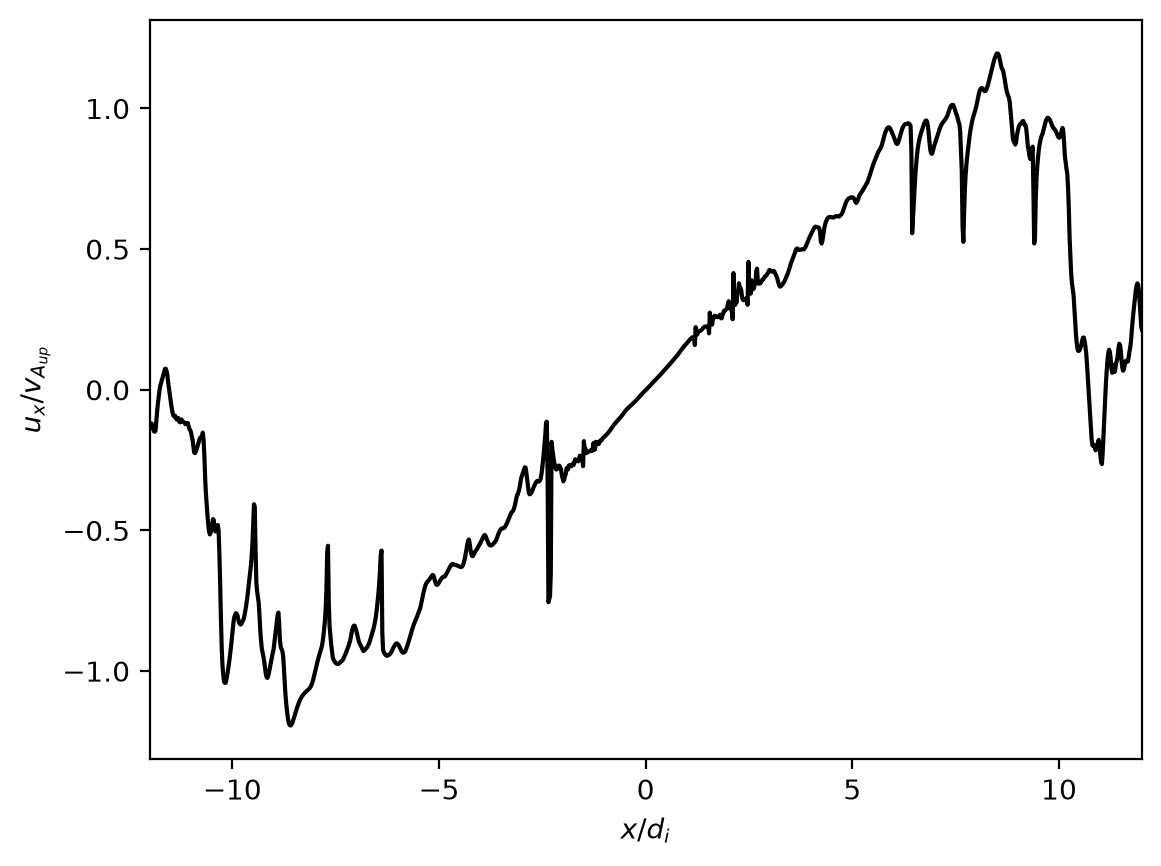

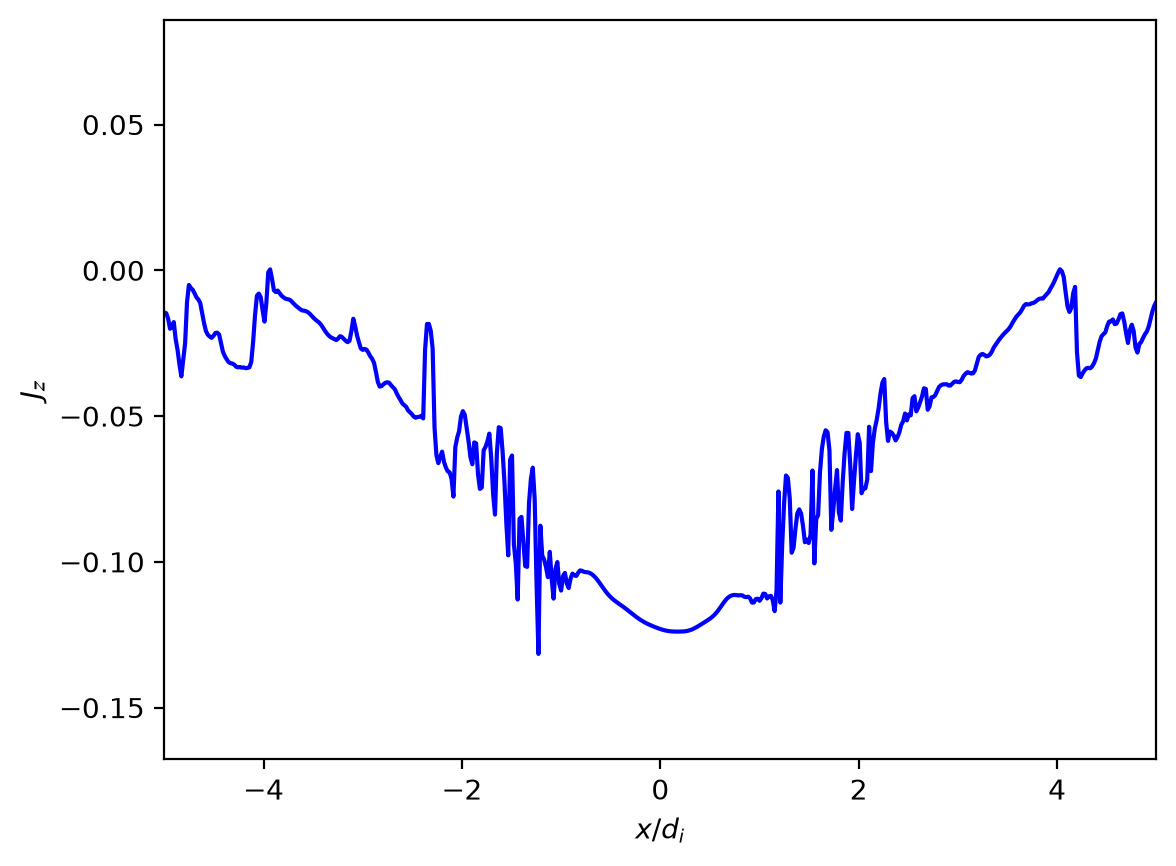

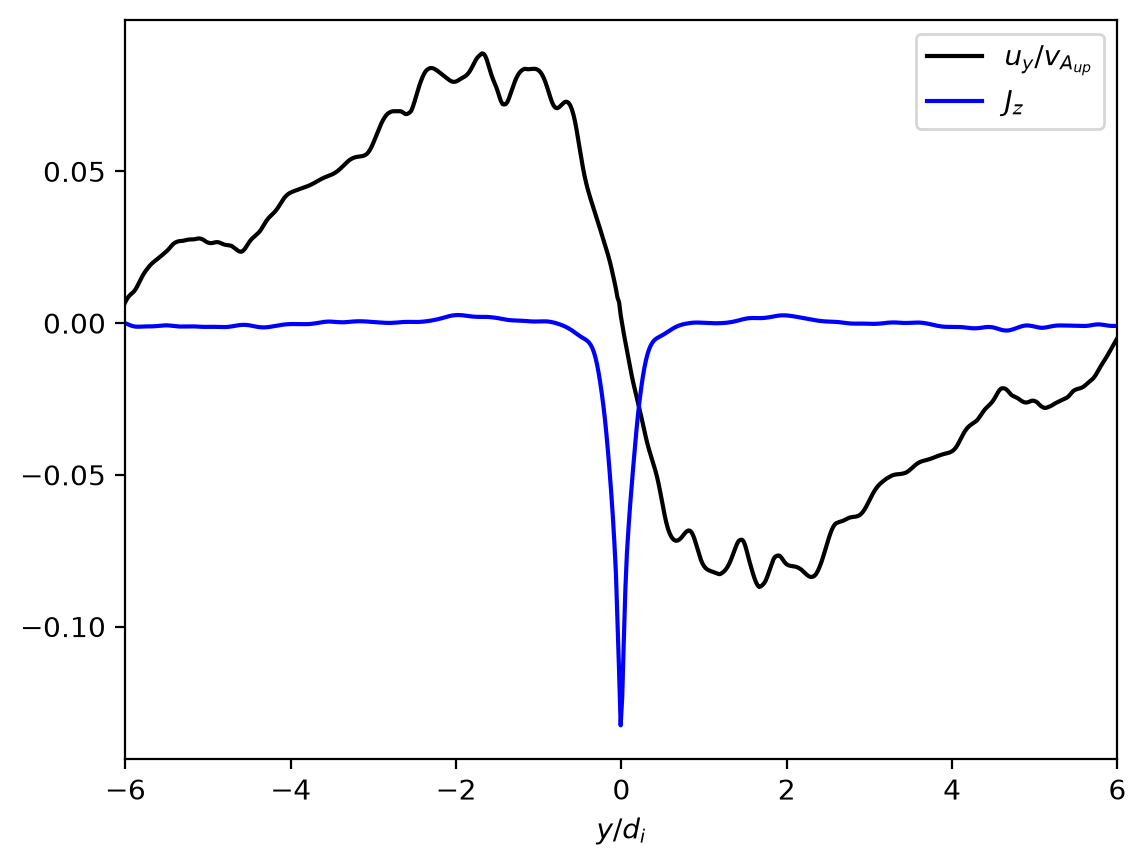

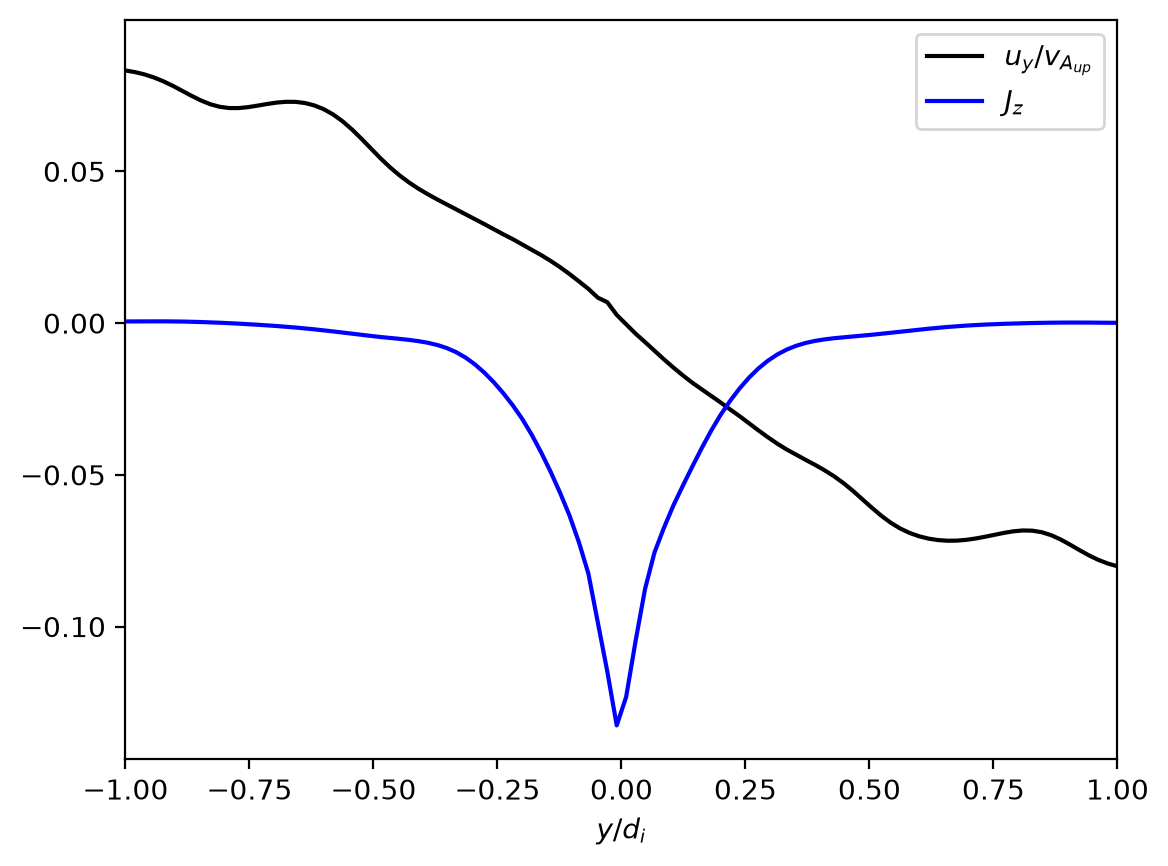

In [ ]:
ux_norm0_y0 = ux_norm0[..., int(Ny_1 / 2)]
Jz_y0 = Jz_1[..., int(Ny_1 / 2)]
plt.figure()
plt.plot(r_coords_1[0] / di, ux_norm0_y0, 'k')
plt.xlabel('$x/d_i$')
plt.ylabel('$u_x/v_{A_{up}}$')
plt.xlim(-12, 12)
plt.figure()
plt.plot(r_coords_1[0] / di, Jz_y0, 'b')
plt.xlabel('$x/d_i$')
plt.ylabel('$J_z$')
plt.xlim(-5, 5)
uy = five_moment.yvel(data_ion_1).get_values()
uy_x0 = uy[int(Nx_1 / 2), ..., 0] / vA_up
Jz_x0 = Jz_1[int(Nx_1 / 2), ...]
plt.figure()
plt.plot(r_coords_1[1] / di, uy_x0, 'k', label='$u_y/v_{A_{up}}$')
plt.plot(r_coords_1[1] / di, Jz_x0, 'b', label='$J_z$')
plt.xlabel('$y/d_i$')
plt.xlim(-6, 6)
plt.legend(loc='best')
plt.figure()
plt.plot(r_coords_1[1] / di, uy_x0, 'k', label='$u_y/v_{A_{up}}$')
plt.plot(r_coords_1[1] / di, Jz_x0, 'b', label='$J_z$')
plt.xlabel('$y/d_i$')
plt.xlim(-1, 1)
plt.legend(loc='best')
plt.show()